## 0. Data

In [16]:
pip install xlrd

Note: you may need to restart the kernel to use updated packages.


In [21]:
import pandas as pd
url = "http://byungwan.com/class/House_Prices.xls"
house = pd.read_excel(url)
house.head()

,HomeID,Price,SqFt,Bedrooms,Bathrooms,Offers,Brick,Neighborhood
0,1,114300,1790,2,2,2,No,East
1,2,114200,2030,4,2,3,No,East
2,3,114800,1740,3,2,1,No,East
3,4,94700,1980,3,2,3,No,East
4,5,119800,2130,3,3,3,No,East


In [22]:
house.isnull().values.any()

np.False_

In [23]:
house2 = pd.get_dummies(house, columns=["Brick", "Neighborhood"], drop_first=True, dtype=int)
house2.head()

,HomeID,Price,SqFt,Bedrooms,Bathrooms,Offers,Brick_Yes,Neighborhood_North,Neighborhood_West
0,1,114300,1790,2,2,2,0,0,0
1,2,114200,2030,4,2,3,0,0,0
2,3,114800,1740,3,2,1,0,0,0
3,4,94700,1980,3,2,3,0,0,0
4,5,119800,2130,3,3,3,0,0,0


## 1. Linear Regression

In [24]:
house2.columns.get_loc("Price")

1

In [54]:
y = house2.iloc[:, 1]

In [26]:
x = house2.iloc[:, 2:]

In [27]:
x.head()

,SqFt,Bedrooms,Bathrooms,Offers,Brick_Yes,Neighborhood_North,Neighborhood_West
0,1790,2,2,2,0,0,0
1,2030,4,2,3,0,0,0
2,1740,3,2,1,0,0,0
3,1980,3,2,3,0,0,0
4,2130,3,3,3,0,0,0


In [28]:
from statsmodels import api as sm

In [31]:
reg = sm.OLS(y,x).fit()
print(reg.summary())

                                 OLS Regression Results                                
Dep. Variable:                  Price   R-squared (uncentered):                   0.995
Model:                            OLS   Adj. R-squared (uncentered):              0.994
Method:                 Least Squares   F-statistic:                              3239.
Date:                Tue, 29 Sep 2026   Prob (F-statistic):                   2.09e-134
Time:                        10:45:45   Log-Likelihood:                         -1356.7
No. Observations:                 128   AIC:                                      2727.
Df Residuals:                     121   BIC:                                      2747.
Df Model:                           7                                                  
Covariance Type:            nonrobust                                                  
                         coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------

In [38]:
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif

In [39]:
x.shape

(128, 7)

In [43]:
vif_values = [float(vif(x.values, i)) for i in range(0,7)]
vif_values

[57.60775699450441,
 31.028044452273534,
 35.632901553298055,
 10.591655827582377,
 1.6377236928141587,
 2.1213648792322646,
 2.4362969178112834]

In [47]:
vif_labels = x.columns

In [48]:
vif_table = pd.DataFrame({"Variable": vif_labels, "VIF Factor": vif_values})

In [49]:
vif_table

,Variable,VIF Factor
0,SqFt,57.607757
1,Bedrooms,31.028044
2,Bathrooms,35.632902
3,Offers,10.591656
4,Brick_Yes,1.637724
5,Neighborhood_North,2.121365
6,Neighborhood_West,2.436297


In [60]:
house2.head()

,HomeID,Price,SqFt,Bedrooms,Bathrooms,Offers,Brick_Yes,Neighborhood_North,Neighborhood_West
0,1,114300,1790,2,2,2,0,0,0
1,2,114200,2030,4,2,3,0,0,0
2,3,114800,1740,3,2,1,0,0,0
3,4,94700,1980,3,2,3,0,0,0
4,5,119800,2130,3,3,3,0,0,0


In [61]:
x2 = house2.iloc[:, [2,6,7,8]]

In [63]:
reg2 = sm.OLS(y,x2).fit()
print(reg2.summary())

                                 OLS Regression Results                                
Dep. Variable:                  Price   R-squared (uncentered):                   0.991
Model:                            OLS   Adj. R-squared (uncentered):              0.991
Method:                 Least Squares   F-statistic:                              3495.
Date:                Tue, 29 Sep 2026   Prob (F-statistic):                   2.12e-126
Time:                        11:10:46   Log-Likelihood:                         -1388.9
No. Observations:                 128   AIC:                                      2786.
Df Residuals:                     124   BIC:                                      2797.
Df Model:                           4                                                  
Covariance Type:            nonrobust                                                  
                         coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------

In [59]:
residual = reg2.resid
residual

0      10934.553931
1      -3024.500291
2      14321.856893
3     -19637.197328
4      -3199.106217
           ...     
123    -9611.744415
124     3574.280178
125    -2382.927650
126     2152.971017
127    -1677.218316
Length: 128, dtype: float64

In [65]:
x2_c = sm.add_constant(x2)

In [68]:
bp_test = sm.stats.het_breuschpagan(residual, x2_c)
bp_test

(np.float64(3.66131481047006),
 np.float64(0.4537774397798833),
 np.float64(0.9054738696194172),
 np.float64(0.4630708095298731))

In [70]:
bp_test2 = [float(b) for b in bp_test]
bp_test2

[3.66131481047006, 0.4537774397798833, 0.9054738696194172, 0.4630708095298731]

In [71]:
bp_label = ["LM Statistics","LM p-value", "F Statistics", "F p-value"]

In [75]:
pd.DataFrame(bp_test, columns = ["Value"], index=bp_label)

,Value
LM Statistics,3.661315
LM p-value,0.453777
F Statistics,0.905474
F p-value,0.463071


In [77]:
reg3 = sm.OLS(y,x2).fit(cov_type="HC3")
print(reg3.summary())

                                 OLS Regression Results                                
Dep. Variable:                  Price   R-squared (uncentered):                   0.991
Model:                            OLS   Adj. R-squared (uncentered):              0.991
Method:                 Least Squares   F-statistic:                              3560.
Date:                Tue, 29 Sep 2026   Prob (F-statistic):                   6.90e-127
Time:                        11:21:31   Log-Likelihood:                         -1388.9
No. Observations:                 128   AIC:                                      2786.
Df Residuals:                     124   BIC:                                      2797.
Df Model:                           4                                                  
Covariance Type:                  HC3                                                  
                         coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------

In [79]:
y_pred = reg3.predict()

In [81]:
from matplotlib import pyplot as plt
import seaborn as sns

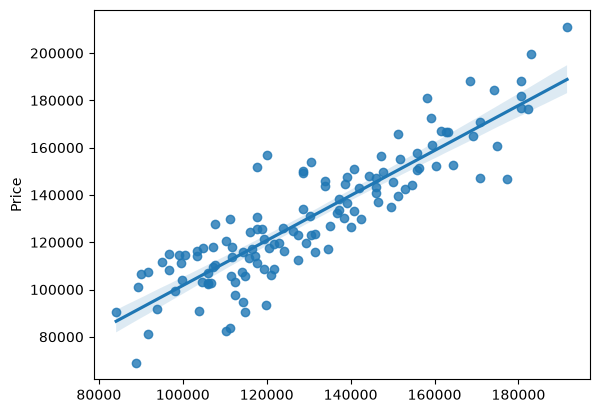

In [84]:
sns.regplot(x = y_pred, y = y)
plt.show()

In [85]:
residual = reg3.resid

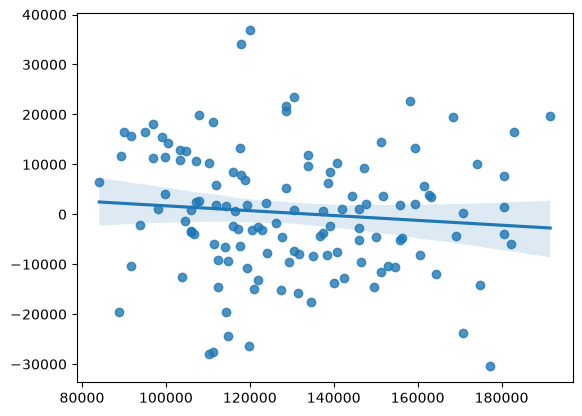

In [87]:
sns.regplot(x = y_pred, y = residual)
plt.show()

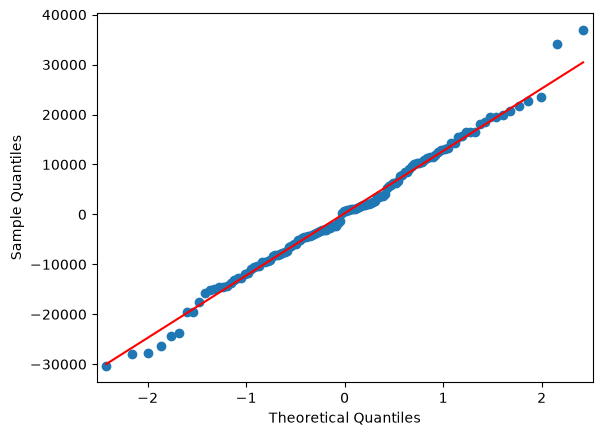

In [96]:
sm.qqplot(residual, line="s")
plt.show()